# PINN دوطرفهٔ سیال–ذره با کرنل گاوسی نرمال‌شده

**نسخهٔ مرحلهٔ اول: شبکهٔ میدان سیال + شبکهٔ حرکت ذره؛ حل هم‌زمان معادلات PDE و ODE در تابع هزینه.**

این فایل مستقل است. روی Kaggle/Colab سلول‌ها را به ترتیب اجرا کنید؛ وزن‌های یک‌طرفهٔ قبلی با این مدل سازگار نیستند. مدل سیال ناپایاست و دیگر loss استقلال از شرایط اولیهٔ ذره ندارد. مسیر نهایی PINN از خروجی شبکهٔ ذره می‌آید. حل MAC سبک برای آموزش کمکی اختیاری و شبکهٔ ریزتر جدا برای اعتبارسنجی استفاده می‌شوند.

**پیش‌فرض یک ذره است.** با `sides=(0,1)` دو ذره از دو دیواره در **یک میدان مشترک** حل می‌شوند؛ تا ۴ ذره قابل انتخاب است. منبع نیروهای ذرات جمع می‌شود، اما جواب‌های مستقل ناویر–استوکس روی هم جمع نمی‌شوند. در میدان مشترک، برهم‌کنش غیرمستقیم ذرات از طریق سیال حضور دارد؛ نیروی تماس مستقیم، برخورد و روان‌کاری نزدیک‌تماس مدل نشده‌اند.

در این مرحله همهٔ ذرات در `t=0` با شرایط اولیهٔ معلوم داخل کانال حاضرند. زمان رهاسازیِ متفاوت و برنامهٔ تشکیل شکلِ نسخهٔ قبلی به این مدل منتقل نشده‌اند: آن کار به تعریف تاریخچهٔ مشترک میدان و آزمون جدا نیاز دارد. بازهٔ پیش‌فرض زمان کوتاه است تا ابتدا خود کوپل اعتبارسنجی شود.

**دقت فیزیکی ادعاشده:** این یک مدل اصطکاکی/درگ با سرعت میانگین‌شده و پهنای محدود است؛ حل سطح واقعی کره و نیز روش تصحیح سرعتِ بدون اغتشاشِ ذرات نقطه‌ای نیست. پهنای گاوسی پارامتر مدل است؛ `sigma→0` حد معتبرِ ادعاشده‌ای برای این پیاده‌سازی نیست. آزمون‌های این فایل، صحت پیاده‌سازی و دقت حل همین مدل را می‌سنجند، نه بی‌نقص‌بودن تمام فیزیک ذرهٔ واقعی.


## ۱. مدل ریاضی و مقیاس‌ها

همهٔ متغیرها با $L_0,U_0,L_0/U_0$ بی‌بعدند و $Re=\rho_f U_0 L_0/\mu$ است. سرعت مرجع، سرعت مرکز پوازوی است. دامنه $[0,L]\times[0,H]$ و عمق میانگین‌گیری خارج صفحه $B$ است:

$$m^*=\frac{\rho_p}{\rho_f}\frac{\pi d^3}{6B},\qquad
\tau_p=\frac{(\rho_p/\rho_f)Re\,d^2}{18}.$$

این مقیاس جرم، نیروی سه‌بعدی را با جرم سیال در یک لایهٔ دوبعدی سازگار می‌کند. مدل، میانگین‌گیری در عمق است؛ جریان سه‌بعدی اطراف سطح کره تفکیک نمی‌شود.

$$\partial_t\mathbf{u}+\mathbf{u}\cdot\nabla\mathbf{u}
=-\nabla p+Re^{-1}\nabla^2\mathbf{u}-\sum_i\mathbf{F}_i^*W_i,
\qquad\nabla\cdot\mathbf{u}=0,$$

$$\dot{\mathbf{x}}_i=\mathbf{v}_i,\qquad
\dot{\mathbf{v}}_i=k_i(\bar{\mathbf{u}}_i-\mathbf{v}_i),\qquad
\mathbf{F}_i^*=m^*k_i(\bar{\mathbf{u}}_i-\mathbf{v}_i),$$

$$\bar{\mathbf{u}}_i=\int_\Omega W_i(\mathbf{x})\mathbf{u}(\mathbf{x})\,dA,\qquad
k_i=\tau_p^{-1}f(Re_{p,i}),\qquad Re_{p,i}=Re\,d\,|\bar{\mathbf{u}}_i-\mathbf{v}_i|.$$

مدل درگِ پیش‌فرض شیلر–نومان و گزینهٔ دیگر استوکس است. درگ بر سرعت **میانگین‌شده با کرنل** اعمال می‌شود. این یک بستار اصطکاکی هموارشده است و معادل درگِ مبتنی بر سرعتِ بدون اغتشاشِ کرهٔ واقعی ادعا نمی‌شود. تصحیح اثر خودِ ذره، اثر سطح کره و دیواره، مدل و اعتبارسنجی دیگری می‌خواهند. پهنای کرنل پارامتر مدل است؛ با ریزشدن شبکه آن را خودکار صفر نکنید.

گرانش، شناوری، جرم افزوده، تاریخچه، لیفت، دوران و روان‌کاری نزدیک‌تماس حذف شده‌اند. چگالی بالای پیش‌فرض بعضی ساده‌سازی‌ها را معقول‌تر می‌کند ولی اعتبار تجربی ایجاد نمی‌کند. مرکز اولیه یک شعاع اسمی به‌علاوهٔ gap داخل دیواره است و جت سیال نازل مدل نشده است.

**گاوسی نرمال‌شده در مستطیل:**

$$W_i(\mathbf{x})=
\frac{\exp[-|\mathbf{x}-\mathbf{x}_i|^2/(2\sigma^2)]}
{2\pi\sigma^2 Z_{x,i}Z_{y,i}},\qquad
Z_{r,i}=\Phi((r_{\max}-r_i)/\sigma)-\Phi(-r_i/\sigma).$$

انتگرال کرنل حتی نزدیک دیواره برابر ۱ است. همان کرنل برای خواندن سرعت و پخش نیرو استفاده می‌شود؛ تبادل نیرو متقارن و توان تبادل داخلی نامثبت است:

$$\int_\Omega\mathbf{u}\cdot\mathbf{s}\,dA+
\sum_i\mathbf{v}_i\cdot\mathbf{F}_i^*
=-\sum_i m^* k_i|\bar{\mathbf{u}}_i-\mathbf{v}_i|^2\leq0.$$

این به معنی ثابت‌بودن انرژی یا مومنتوم کل کانال نیست؛ فشار ورودی، خروج جرم و تنش دیواره سهم جدا دارند. ممیزی این فایل فقط **تبادل داخلی بین دو فاز** را بررسی می‌کند.

یک قید کمکی سازگار برای فشار نیز در loss قرار دارد:

$$\nabla^2p+\sum_{j,k}(\partial_j u_k)(\partial_k u_j)-\nabla\cdot\mathbf{s}=0.$$

این معادله از واگرایی مومنتوم و پیوستگی می‌آید. مشتق منبع گاوسی با علامت همان نیروی عکس‌العمل تحلیلی محاسبه می‌شود.


## ۲. شبکه‌ها، ورودی‌ها و نوع آموزش

برای هر ذره $c_i=(x_{i,0},u_{i,0},w_{i,0})$ داریم. $w_{i,0}>0$ اندازهٔ سرعت رو به داخل است و علامت عمودی را دیوارهٔ معلوم در sides تعیین می‌کند. $y_{i,0}$ از دیواره، شعاع اسمی و gap تعیین می‌شود.

| شبکه | ورودی فیزیکی | خروجی |
|---|---|---|
| FluidPINN | $x,y,t,c_1,\ldots,c_N$ | تابع جریان اغتشاش و تصحیح فشار؛ سپس $u,v,p$ با مشتق‌گیری |
| ParticlePINN | $t,c_1,\ldots,c_N$ | $x_i,y_i,u_i,v_i$ برای همهٔ ذرات |

برای دو ذره، یکی از هر دیواره، شبکهٔ سیال **۹ ورودی فیزیکی** دارد. برای یک ذره ۶ ورودی کافی است. برای بیش از دو ذره، همان شش کنترل اولیه برای توصیف همهٔ سامانه کافی نیست. یک میدان مشترک، همهٔ ذرات فعالِ همان سناریو را می‌بیند.

کدگذاری اختیاری و قطعیِ فاصله تا مراکز بالستیک اولیه به ویژگی‌های داخلی MLP اضافه می‌شود. این دادهٔ حل مرجع یا مسیر تحمیلی نیست؛ محل واقعی منبع نیرو همیشه از شبکهٔ ذره می‌آید. تعداد ویژگی‌های داخلی با ورودی‌های فیزیکی فرق دارد.

**پیوستگی و شار سخت:** پیش‌فرض streamfunction=True است:

$$\psi'=\chi(t)G(x,t,c)\,4H(x/L)^2(y/H)^2(1-y/H)^2N_\psi,\qquad
u=u_{\mathrm{Pois}}+\partial_y\psi',\quad v=-\partial_x\psi'.$$

پیش‌فرض $\chi(t)=1-\exp[-t/(Re\sigma^2)]$ است؛ این یک نمایش مناسبِ شروع گذرای سریع در مقیاس گاوسی است و پاسخ فیزیکی را تجویز نمی‌کند، چون دامنهٔ عصبی آزاد است. نیروی واقعی از زمان صفر با شدت کامل اعمال می‌شود. $G$ یک پوشش نرم گاوسی در راستای x با پهنای ارتفاع کانال و مراکز بالستیک اولیه است؛ فشار پوشش موضعی ندارد. این قید نمایشی برای افق کوتاه و جریان آرام این مثال است، نه بیدارِ آشفته یا دامنهٔ زمانی نامحدود. می‌توان آن را با localized_streamfunction=False و نمایش زمان را با viscous_time_gate=False خاموش کرد و دوباره آموزش داد.

تراکم‌ناپذیری، شار، شرط سرعت ورودی، سرعت اولیهٔ سیال و بدون لغزش دو دیواره سخت برقرار می‌شوند. مشتق‌های PDE تا مرتبهٔ سوم شبکه هستند.

ورودی پوازوی است؛ خروجی فشار صفر و مشتق نرمال سرعت صفر به‌صورت نرم دارد. میدان داخلی و پروفیل خروجی در زمان‌های بعد به پوازوی ثابت مجبور نمی‌شوند. **فشار شرط اولیهٔ پوازوی ندارد** چون فوراً به نیروی ذره پاسخ می‌دهد.

شرایط اولیهٔ مکان و سرعت ذرات سخت‌اند. معادله‌های زمانی با مشتق‌گیری خودکار وارد loss می‌شوند. بعد از آموزش ODE عددی جای شبکهٔ ذره را نمی‌گیرد.

**دو حالت آموزش:**

- USE_COARSE_FLUID_DATA=True، پیش‌فرض عملی: میدان MAC روی شبکهٔ ۹۶×۳۶ به آموزش کمک می‌کند؛ معادلات PDE و ODE همچنان حضور دارند. در حالت تابع جریان، مقدار تابع جریان از انتگرال سرعت شبکه‌ای ساخته می‌شود و به‌همراه فشار آموزش کمکی می‌دهد؛ این از آموزش مشتق‌های سرعت پایدارتر است. فقط سیال برچسب دارد، نه مسیر ذره. یک پیش‌آموزش کمکی و سپس آموزش مشترک کامل انجام می‌شود. اعتبارسنجی نهایی روی شبکه‌های **جدا و ریزتر**، ۱۲۸×۴۸ و ۱۶۰×۶۰، انجام می‌شود. این حالت PINN با دادهٔ کمکی عددی است و داده‌آزاد نامیده نمی‌شود.
- False: آموزش صرفاً فیزیکی. برای دقت اغتشاش ضعیف ممکن است آموزش بیشتر یا تنظیم دقیق‌تر لازم شود؛ پذیرش در این حالت هم به تمام آزمون‌ها وابسته است.

پیش‌فرض parametric=False یک سناریوی مشخص است. parametric=True شرایط اولیه را در جعبهٔ محدود نمونه‌برداری می‌کند و آموزش دوباره می‌خواهد. دادهٔ کمکیِ اسمی به‌تنهایی دقت در کل جعبه را اثبات نمی‌کند؛ نمونه‌های دیده‌نشده را جدا اعتبارسنجی کنید.


In [1]:
import sys, subprocess, importlib.util
required={'numpy':'numpy','scipy':'scipy','matplotlib':'matplotlib','torch':'torch','IPython':'ipython'}
missing=[p for m,p in required.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.run([sys.executable,'-m','pip','install','-q',*missing],check=True)


In [2]:
from dataclasses import dataclass, asdict, replace
from pathlib import Path
import json, time, math, copy, csv, shutil
import numpy as np
import torch
from torch import nn
from scipy.special import ndtr, ndtri
import matplotlib.pyplot as plt
from IPython.display import display, HTML, FileLink

@dataclass
class Settings:
    L: float = 2.2
    H: float = .30
    U: float = 1.
    Re: float = 10.
    diameter: float = .025
    density_ratio: float = 1000.
    depth: float = 1.  # dimensionless out-of-plane averaging depth B/L0
    sigma: float = .035
    gap: float = 1e-5
    T: float = .12
    sides: tuple = (0,)  # 0 bottom; (0,1) solves TWO particles in ONE fluid field
    width: int = 96
    layers: int = 3
    quad_order: int = 12
    groups: int = 6
    uniform_points: int = 48
    near_points: int = 32
    adam_steps: int = 4000
    lbfgs_steps: int = 120
    report_every: int = 200
    lr: float = 8e-4
    seed: int = 42
    drag: str = 'schiller-naumann'
    parametric: bool = False
    device: str = 'cuda' if torch.cuda.is_available() else 'cpu'
    # Current scenario: [x0,u0,inward speed] for EACH particle. Defaults are generated below.
    scenario: tuple = ()
    force_scale: float = 1.  # diagnostic only: zero = one-way control experiment
    local_features: bool = True  # deterministic encoding; no reference-solution data
    streamfunction: bool = True  # exact incompressibility and exact through-flow
    pressure_poisson_weight: float = .3
    localized_streamfunction: bool = True
    viscous_time_gate: bool = True

    def __post_init__(self):
        self.sides=tuple(int(s) for s in self.sides)
        assert self.sides and len(self.sides)<=4 and set(self.sides)<={0,1}
        assert min(self.L,self.H,self.Re,self.diameter,self.density_ratio,self.depth,self.T,self.sigma)>0
        assert self.diameter+2*self.gap<self.H and self.drag in ('stokes','schiller-naumann')
        assert self.quad_order>=4 and self.groups>=2
        if len(self.scenario)==0:
            self.scenario=tuple(v for i in range(len(self.sides))
                                for v in (.42*self.L+.16*i, .45, .35))
        self.scenario=tuple(float(v) for v in self.scenario)
        assert len(self.scenario)==3*len(self.sides)
        c=np.asarray(self.scenario).reshape(-1,3)
        assert np.isfinite(c).all()
        assert np.all((c[:,0]>.1*self.L)&(c[:,0]<.85*self.L))
        assert np.all(c[:,2]>0)

    @property
    def n(self):return len(self.sides)
    @property
    def mass(self):return self.density_ratio*np.pi*self.diameter**3/(6*self.depth)
    @property
    def tau(self):return self.density_ratio*self.Re*self.diameter**2/18


def tensor(a,cfg,grad=False):
    return torch.as_tensor(a,dtype=torch.float64,device=cfg.device).requires_grad_(grad)

def controls_box(cfg):
    # Inward speed is positive; the side supplies the physical y-velocity sign.
    lo=np.tile([.25*cfg.L,.10,.15],cfg.n)
    hi=np.tile([.70*cfg.L,.90,.55],cfg.n)
    return lo,hi

def sample_controls(cfg,count,rng):
    if not cfg.parametric:return np.tile(cfg.scenario,(count,1))
    lo,hi=controls_box(cfg)
    c=rng.uniform(lo,hi,(count,3*cfg.n))
    c[0]=cfg.scenario
    return c

def mlp(inputs,outputs,cfg):
    layers=[nn.Linear(inputs,cfg.width),nn.Tanh()]
    for _ in range(cfg.layers-1):layers += [nn.Linear(cfg.width,cfg.width),nn.Tanh()]
    layers += [nn.Linear(cfg.width,outputs)]
    net=nn.Sequential(*layers).to(device=cfg.device,dtype=torch.float64)
    for m in net:
        if isinstance(m,nn.Linear):nn.init.xavier_normal_(m.weight);nn.init.zeros_(m.bias)
    with torch.no_grad():net[-1].weight.mul_(.02)
    return net

class CoupledPINN(nn.Module):
    """Fluid input [x,y,t,ALL initial triplets]; particle input [t,ALL triplets].

    Each triplet is x0, u0, inward_speed, with sides fixed in cfg.
    All particles are active at t=0. There is one shared fluid field.
    No initial condition is reused as an artificial prescribed particle path.
    """
    def __init__(self,cfg):
        super().__init__();self.cfg=cfg
        self.fluid_net=mlp(3+3*cfg.n+(3*cfg.n if cfg.local_features else 0),2 if cfg.streamfunction else 3,cfg)
        self.particle_net=mlp(1+3*cfg.n,4*cfg.n,cfg)
        lo,hi=controls_box(cfg)
        self.register_buffer('c_mid',tensor((lo+hi)/2,cfg))
        self.register_buffer('c_span',tensor(hi-lo,cfg))
        nodes,weights=np.polynomial.legendre.leggauss(cfg.quad_order)
        rr,ss=np.meshgrid((nodes+1)/2,(nodes+1)/2,indexing='ij')
        ww=np.outer(weights,weights).ravel()/4
        self.register_buffer('qr',tensor(np.c_[rr.ravel(),ss.ravel()],cfg))
        self.register_buffer('qw',tensor(ww,cfg))
        self.register_buffer('sign',tensor([1 if s==0 else -1 for s in cfg.sides],cfg))
        self.register_buffer('y0',tensor([cfg.diameter/2+cfg.gap if s==0 else
                                        cfg.H-cfg.diameter/2-cfg.gap for s in cfg.sides],cfg))

    def normalize_c(self,c):return 2*(c-self.c_mid)/self.c_span

    def fluid(self,z):
        # A streamfunction needs coordinate derivatives even during plotting.
        # Preserve incoming graphs for quadrature/particle gradients during training.
        with torch.enable_grad():
            if not z.requires_grad:z=z.detach().requires_grad_(True)
            return self._fluid(z)

    def psi(self,z):
        with torch.enable_grad():
            if not z.requires_grad:z=z.detach().requires_grad_(True)
            return self._fluid(z,psi_only=True)

    def _fluid(self,z,psi_only=False):
        cfg=self.cfg;x,y,t=z[...,0],z[...,1],z[...,2]
        X,Y,A=x/cfg.L,y/cfg.H,t/cfg.T
        inputs=torch.cat((torch.stack((2*X-1,2*Y-1,2*A-1),-1),self.normalize_c(z[...,3:])), -1)
        if cfg.local_features:
            # Ballistic centers are encoding features ONLY. The source and accepted
            # trajectory always use the independently learned particle-network state.
            ic=z[...,3:].reshape(-1,cfg.n,3)
            cx=ic[:,:,0]+t[:,None]*ic[:,:,1]
            cy=self.y0+t[:,None]*ic[:,:,2]*self.sign
            dx=(x[:,None]-cx)/cfg.sigma;dy=(y[:,None]-cy)/cfg.sigma
            features=torch.stack((torch.tanh(dx/2),torch.tanh(dy/2),torch.exp(-.5*(dx*dx+dy*dy))),-1)
            inputs=torch.cat((inputs,features.flatten(1)),-1)
        raw=self.fluid_net(inputs)
        # Initial velocity, inlet and no-slip walls are exact. Outlet velocity is FREE.
        envelope=4*Y*(1-Y)*X
        if cfg.streamfunction:
            # Representation of the fast viscous startup at the Gaussian scale.
            # This enforces only the initial value, NOT an imposed solution:
            # the neural amplitude remains free and the FULL force acts at t=0.
            rise=-torch.expm1(-t/(cfg.Re*cfg.sigma**2)) if cfg.viscous_time_gate else A
            psi=rise*4*cfg.H*X.square()*Y.square()*(1-Y).square()*raw[:,0]
            if cfg.localized_streamfunction:
                # Smooth representation prior for the short-time, low-Re channel
                # disturbance. This is NOT the force kernel and does not alter
                # Gaussian normalization or the coupling equations. Pressure
                # remains global. No particle trajectory is prescribed here.
                ic=z[...,3:].reshape(-1,cfg.n,3)
                centers=ic[:,:,0]+t[:,None]*ic[:,:,1]
                local=torch.exp(-.5*((x[:,None]-centers)/cfg.H).square()).sum(1)
                psi=psi*local
            if psi_only:return psi
            grad=torch.autograd.grad(psi,z,torch.ones_like(psi),create_graph=True,retain_graph=True)[0]
            u=4*cfg.U*Y*(1-Y)+grad[:,1]
            v=-grad[:,0]
        else:
            u=4*cfg.U*Y*(1-Y)+A*envelope*.6*raw[...,0]
            v=A*envelope*.6*raw[...,1]
        # No pressure initial condition: pressure adjusts instantaneously to forcing.
        p=8*cfg.U*(cfg.L-x)/(cfg.Re*cfg.H**2)+(1-X)*2*raw[...,-1]
        return torch.stack((u,v,p),-1)

    def particles(self,tc):
        cfg=self.cfg;t=tc[:,0:1];c=tc[:,1:];ic=c.reshape(-1,cfg.n,3)
        r=self.particle_net(torch.cat((2*t/cfg.T-1,self.normalize_c(c)),-1)).reshape(-1,cfg.n,4)
        vy0=ic[:,:,2]*self.sign
        # Exact positions/velocities at t=0, plus exact initial kinematic derivatives.
        x=ic[:,:,0]+t*ic[:,:,1]+t*t/cfg.T*.6*r[:,:,0]
        y=self.y0+t*vy0+t*t/cfg.T*.6*r[:,:,1]
        vx=ic[:,:,1]+t/cfg.T*.8*r[:,:,2]
        vy=vy0+t/cfg.T*.8*r[:,:,3]
        return torch.stack((x,y,vx,vy),-1)

    def quadrature(self,q):
        """Differentiable Gaussian expectation on the ENTIRE truncated rectangle.

        Gauss-Legendre in probability space + inverse normal CDF; weights sum to 1.
        This does not truncate a Gaussian at an arbitrary multiple of sigma.
        q may depend on trainable particle coordinates; gradients remain connected.
        """
        cfg=self.cfg
        limits=tensor([cfg.L,cfg.H],cfg)
        cdf0=.5*(1+torch.erf((-q/cfg.sigma)/math.sqrt(2)))
        cdf1=.5*(1+torch.erf(((limits-q)/cfg.sigma)/math.sqrt(2)))
        prob=cdf0[...,None,:]+self.qr*(cdf1-cdf0)[...,None,:]
        points=q[...,None,:]+cfg.sigma*math.sqrt(2)*torch.erfinv(2*prob.clamp(1e-12,1-1e-12)-1)
        return points

    def kernel(self,xy,q):
        # xy: G,P,2; q: G,N,2 -> G,P,N, normalized continuously on the rectangle.
        cfg=self.cfg;lim=tensor([cfg.L,cfg.H],cfg)
        z=(.5*(torch.erf((lim-q)/(cfg.sigma*math.sqrt(2))) -
              torch.erf(-q/(cfg.sigma*math.sqrt(2))))).prod(-1)
        if bool((z.detach()<1e-12).any()):
            raise FloatingPointError('Particle moved too far outside the kernel domain; reject this training iterate.')
        delta=(xy[:,:,None,:]-q[:,None,:,:])/cfg.sigma
        return torch.exp(-.5*(delta*delta).sum(-1))/(2*np.pi*cfg.sigma**2*z[:,None,:])

    def exchange(self,tc,state=None):
        cfg=self.cfg
        if state is None:state=self.particles(tc)
        points=self.quadrature(state[:,:,:2]);g,n,k,_=points.shape
        packed=torch.cat((points,tc[:,None,None,:].expand(g,n,k,1+3*n)),-1)
        uv=self.fluid(packed.reshape(-1,3+3*n))[:,:2].reshape(g,n,k,2)
        average=(uv*self.qw[None,None,:,None]).sum(2)
        slip=average-state[:,:,2:]
        rep=cfg.Re*cfg.diameter*torch.sqrt((slip*slip).sum(-1)+1e-24)
        factor=torch.ones_like(rep) if cfg.drag=='stokes' else torch.where(
            rep<1000,1+.15*rep.pow(.687),.44*rep/24)
        coefficient=factor/cfg.tau
        acceleration=coefficient[...,None]*slip
        force=cfg.mass*acceleration
        return dict(average=average,slip=slip,force=force,acceleration=acceleration,
                    coefficient=coefficient,rep=rep)


def derivative(value,inputs):
    return torch.autograd.grad(value,inputs,torch.ones_like(value),create_graph=True,
                               retain_graph=True)[0]

def fluid_residual(field,z,Re,extra=False):
    f=field(z);u,v,p=f.unbind(-1)
    du,dv,dp=[derivative(a,z) for a in (u,v,p)]
    uxx=derivative(du[:,0],z)[:,0];uyy=derivative(du[:,1],z)[:,1]
    vxx=derivative(dv[:,0],z)[:,0];vyy=derivative(dv[:,1],z)[:,1]
    rx=du[:,2]+u*du[:,0]+v*du[:,1]+dp[:,0]-(uxx+uyy)/Re
    ry=dv[:,2]+u*dv[:,0]+v*dv[:,1]+dp[:,1]-(vxx+vyy)/Re
    result=(torch.stack((rx,ry),-1),du[:,0]+dv[:,1])
    if extra:
        plap=derivative(dp[:,0],z)[:,0]+derivative(dp[:,1],z)[:,1]
        conv_div=du[:,0].square()+2*du[:,1]*dv[:,0]+dv[:,1].square()
        return (*result,plap+conv_div)
    return result

def training_batch(model,rng,fixed=False):
    cfg=model.cfg;g=cfg.groups
    t=cfg.T*rng.random((g,1));t[0]=0
    c=sample_controls(cfg,g,rng)
    tc=tensor(np.c_[t,c],cfg,True)
    # Near-source samples are chosen from current positions, but positions are
    # detached ONLY for choosing collocation locations, never for the source force.
    with torch.no_grad():q=model.particles(tc)[:,:,:2].cpu().numpy()
    uniform=rng.uniform([0,0],[cfg.L,cfg.H],(g,cfg.uniform_points,2))
    near=np.stack([q[k,rng.integers(cfg.n,size=cfg.near_points)]+
                    cfg.sigma*rng.normal(size=(cfg.near_points,2)) for k in range(g)])
    # Reflect samples into the rectangle, rather than placing masses of points on walls.
    lim=np.array([cfg.L,cfg.H]);near=lim-np.abs((near%(2*lim))-lim)
    xy=np.concatenate((uniform,near),1)
    xytc=torch.cat((tensor(xy,cfg),tc[:,None,:].expand(g,xy.shape[1],tc.shape[1])),-1)
    # Independent coordinate leaf: partial t derivatives hold controls fixed.
    z=xytc.detach().reshape(-1,3+3*cfg.n).requires_grad_(True)
    return tc,z,xy.shape[1]

def losses(model,batch):
    cfg=model.cfg;tc,z,pcount=batch;g=len(tc)
    state=model.particles(tc);exchange=model.exchange(tc,state)
    source=-cfg.force_scale*torch.einsum('gpn,gnk->gpk',
                  model.kernel(z[:,:2].reshape(g,pcount,2),state[:,:,:2]),exchange['force'])
    r,div,pp=fluid_residual(model.fluid,z,cfg.Re,extra=True)
    # s is acceleration per unit fluid mass, with 3D particle force / 2D depth scaling.
    momentum=((r-source.reshape(-1,2))**2).mean()
    continuity=(div*div).mean()
    kernels=model.kernel(z[:,:2].reshape(g,pcount,2),state[:,:,:2])
    delta=z[:,:2].reshape(g,pcount,1,2)-state[:,None,:,:2]
    div_source=cfg.force_scale*(kernels*(delta*exchange['force'][:,None]).sum(-1)/cfg.sigma**2).sum(-1)
    pressure_poisson=((cfg.sigma*(pp-div_source.reshape(-1)))**2).mean()
    dstate=torch.stack([derivative(state[:,:,j].sum(1),tc)[:,0] for j in range(4)],-1) if cfg.n==1 else None
    # For N>1 compute each derivative separately, never sum particle trajectories.
    if cfg.n==1:dstate=dstate[:,None,:]
    else:
        dstate=torch.stack([torch.stack([derivative(state[:,i,j],tc)[:,0] for j in range(4)],-1)
                            for i in range(cfg.n)],1)
    kin=((dstate[:,:,:2]-state[:,:,2:])**2).mean()
    dyn=((dstate[:,:,2:]-exchange['acceleration'])**2).mean()
    # Standard pressure outlet: p(L,y)=0 is hard; normal velocity derivatives are soft.
    yy=torch.linspace(0,cfg.H,12,device=z.device,dtype=z.dtype)
    out=torch.cat((torch.full((g,len(yy),1),cfg.L,device=z.device,dtype=z.dtype),
                   yy[None,:,None].expand(g,-1,1),tc[:,None,:].expand(g,len(yy),tc.shape[1])),-1)
    out=out.detach().reshape(-1,z.shape[1]).requires_grad_(True)
    uv=model.fluid(out)
    outlet=(derivative(uv[:,0],out)[:,0].square().mean()+
            derivative(uv[:,1],out)[:,0].square().mean())
    # Prevent accepting trajectories that silently leave the model's valid interior.
    q=state[:,:,:2];lo=tensor([cfg.diameter/2,cfg.diameter/2],cfg)
    hi=tensor([cfg.L-cfg.diameter/2,cfg.H-cfg.diameter/2],cfg)
    domain=(torch.relu(lo-q).square()+torch.relu(q-hi).square()).mean()
    # These weights set numerical residual scales, not an artificial force ramp.
    total=momentum+20*continuity+10*kin+dyn+.2*outlet+100*domain+cfg.pressure_poisson_weight*pressure_poisson
    return dict(total=total,momentum=momentum,continuity=continuity,kinematic=kin,
                dynamic=dyn,outlet=outlet,domain=domain,pressure_poisson=pressure_poisson)


def fit(model,run,auxiliary=None):
    cfg=model.cfg;run=Path(run);run.mkdir(exist_ok=True,parents=True)
    model.training_data_used=auxiliary is not None
    rng=np.random.default_rng(cfg.seed);monitor=training_batch(model,np.random.default_rng(cfg.seed+300))
    history=[];best=float('inf');best_state=None;start=time.monotonic()
    monitor_aux=None if auxiliary is None else auxiliary.batch(cfg,np.random.default_rng(cfg.seed+333),128)
    def objective(batch,aux):
        values=losses(model,batch)
        if aux is not None:
            values['fluid_data']=auxiliary.loss(model,aux)
            values['total']=values['total']+values['fluid_data']
        return values
    def record(stage,step):
        nonlocal best,best_state
        vals=objective(monitor,monitor_aux)
        row={k:float(v.detach()) for k,v in vals.items()}
        row.update(stage=stage,step=step,seconds=time.monotonic()-start)
        if not np.isfinite(list(row[k] for k in vals)).all():raise FloatingPointError('Nonfinite monitor')
        history.append(row)
        if row['total']<best:
            best=row['total'];best_state=copy.deepcopy(model.state_dict())
            torch.save(dict(settings=asdict(cfg),state={k:v.cpu() for k,v in best_state.items()},monitor=row,
                            auxiliary_data_used=auxiliary is not None),run/'best_model.pt')
        (run/'training_history.json').write_text(json.dumps(history,indent=2))
        print(json.dumps(row),flush=True)
    record('initial',0)
    opt=torch.optim.Adam(model.parameters(),lr=cfg.lr)
    sched=torch.optim.lr_scheduler.CosineAnnealingLR(opt,max(1,cfg.adam_steps),eta_min=cfg.lr/20)
    for step in range(1,cfg.adam_steps+1):
        aux=None if auxiliary is None else auxiliary.batch(cfg,rng,64)
        opt.zero_grad(set_to_none=True);r=objective(training_batch(model,rng),aux);r['total'].backward()
        norm=torch.nn.utils.clip_grad_norm_(model.parameters(),20.)
        if not torch.isfinite(norm):raise FloatingPointError('Nonfinite gradient')
        opt.step();sched.step()
        if step%cfg.report_every==0:record('Adam',step)
    record('Adam final',cfg.adam_steps);model.load_state_dict(best_state)
    # Freeze a set of collocation coordinates for a valid deterministic line search.
    fixed=training_batch(model,np.random.default_rng(cfg.seed+500))
    fixed_aux=None if auxiliary is None else auxiliary.batch(cfg,np.random.default_rng(cfg.seed+501),256)
    if cfg.lbfgs_steps:
        opt=torch.optim.LBFGS(model.parameters(),lr=.5,max_iter=20,history_size=30,line_search_fn='strong_wolfe')
        for k in range(math.ceil(cfg.lbfgs_steps/20)):
            def closure():
                opt.zero_grad(set_to_none=True);v=objective(fixed,fixed_aux)['total'];v.backward();return v
            opt.step(closure);record('LBFGS',cfg.adam_steps+20*(k+1))
    model.load_state_dict(best_state);model.eval()
    return history



## ۳. حل‌گر مرجع مستقل
این بخش خروجی شبکه‌ای دریافت نمی‌کند. نسخهٔ سبک می‌تواند دادهٔ کمکی بدهد؛ نسخهٔ ریزتر برای اعتبارسنجی نگه داشته می‌شود. حل شبکه‌ای کم‌مرتبهٔ MAC با مشتق‌های مرکزی، گام زمانی midpoint و تصویر هلمهولتز است. خطای شبکه و گام زمانی آن جدا بررسی می‌شوند؛ آن را جواب تحلیلی یا CFD دقیقِ سطح کره تلقی نکنید. تراز تحلیلی جریان پوازوی از معادلات اغتشاش کم می‌شود تا خطای گسسته‌سازی زمینه، بازخورد ضعیف ذره را نپوشاند.

In [3]:
from scipy.sparse import diags, eye, kron
from scipy.sparse.linalg import factorized

class MACReference:
    """Independent NumPy/SciPy staggered-grid reference, no neural predictions.

    Second-order central spatial differences, projected explicit midpoint time
    stepping. The analytical base-flow balance is subtracted exactly. Pressure
    perturbation is zero on the outlet face; homogeneous normal pressure-gradient
    projection conditions apply at the imposed-velocity boundaries. A grid/time
    refinement check is REQUIRED: this low-order reference is not exact CFD.
    """
    def __init__(self,cfg,nx=96,ny=36):
        self.cfg,self.nx,self.ny=cfg,nx,ny
        self.dx,self.dy=cfg.L/nx,cfg.H/ny
        x=np.linspace(0,cfg.L,nx+1);y=(np.arange(ny)+.5)*self.dy
        X,Y=np.meshgrid(x,y);self.uxy=np.stack((X,Y),-1)
        x=(np.arange(nx)+.5)*self.dx;y=np.linspace(0,cfg.H,ny+1)
        X,Y=np.meshgrid(x,y);self.vxy=np.stack((X,Y),-1)
        self.base=4*cfg.U*(self.uxy[...,1]/cfg.H)*(1-self.uxy[...,1]/cfg.H)
        self.wu=np.ones((ny,nx+1))*self.dx*self.dy;self.wu[:,[0,-1]]*=.5
        self.wv=np.ones((ny+1,nx))*self.dx*self.dy;self.wv[[0,-1],:]*=.5
        def axis_matrix(n,h,outlet=False):
            d=np.full(n,2.);d[0]=1;d[-1]=3 if outlet else 1
            return diags([-np.ones(n-1),d,-np.ones(n-1)],[-1,0,1],format='csc')/h**2
        A=kron(eye(ny),axis_matrix(nx,self.dx,True))+kron(axis_matrix(ny,self.dy),eye(nx))
        self.solve=factorized(A.tocsc())

    def div(self,u,v):return np.diff(u,axis=1)/self.dx+np.diff(v,axis=0)/self.dy

    def project(self,u,v):
        phi=self.solve(-self.div(u,v).ravel()).reshape(self.ny,self.nx)
        u=u.copy();v=v.copy()
        u[:,1:-1]-=np.diff(phi,axis=1)/self.dx
        u[:,-1]-=(0-phi[:,-1])/(self.dx/2)
        v[1:-1,:]-=np.diff(phi,axis=0)/self.dy
        return u,v,phi

    def weights(self,points,q,w):
        # Same discrete kernel in reading and spreading; exact discrete normalization.
        k=np.exp(-np.sum((points[None,...]-q[:,None,None,:])**2,axis=-1)/(2*self.cfg.sigma**2))
        return k/np.sum(k*w,axis=(1,2))[:,None,None]

    def rhs(self,state):
        cfg=self.cfg;du,v,q,vp=state;u=du+self.base
        ku=self.weights(self.uxy,q,self.wu);kv=self.weights(self.vxy,q,self.wv)
        avg=np.c_[np.sum(ku*u*self.wu,axis=(1,2)),np.sum(kv*v*self.wv,axis=(1,2))]
        slip=avg-vp;rep=cfg.Re*cfg.diameter*np.linalg.norm(slip,axis=1)
        fac=np.ones_like(rep) if cfg.drag=='stokes' else np.where(rep<1000,1+.15*rep**.687,.44*rep/24)
        acc=fac[:,None]/cfg.tau*slip;force=cfg.mass*acc
        su=-cfg.force_scale*np.einsum('n,nij->ij',force[:,0],ku)
        sv=-cfg.force_scale*np.einsum('n,nij->ij',force[:,1],kv)
        # Velocity at the other component's staggered location.
        vu=np.zeros_like(u);vu[:,1:-1]=.25*(v[:-1,:-1]+v[1:,:-1]+v[:-1,1:]+v[1:,1:])
        vu[:,-1]=.5*(v[:-1,-1]+v[1:,-1])
        uv=np.zeros_like(v);uv[1:-1,:]=.25*(u[:-1,:-1]+u[:-1,1:]+u[1:,:-1]+u[1:,1:])
        up=np.pad(u,((1,1),(1,1)),mode='edge');up[0,1:-1]=-u[0];up[-1,1:-1]=-u[-1]
        dp=np.pad(du,((1,1),(1,1)),mode='edge');dp[0,1:-1]=-du[0];dp[-1,1:-1]=-du[-1]
        vv=np.pad(v,((1,1),(1,1)),mode='edge');vv[1:-1,0]=-v[:,0]
        ux=(up[1:-1,2:]-up[1:-1,:-2])/(2*self.dx)
        uy=(up[2:,1:-1]-up[:-2,1:-1])/(2*self.dy)
        vx=(vv[1:-1,2:]-vv[1:-1,:-2])/(2*self.dx)
        vy=(vv[2:,1:-1]-vv[:-2,1:-1])/(2*self.dy)
        lu=(dp[1:-1,2:]-2*du+dp[1:-1,:-2])/self.dx**2+(dp[2:,1:-1]-2*du+dp[:-2,1:-1])/self.dy**2
        lv=(vv[1:-1,2:]-2*v+vv[1:-1,:-2])/self.dx**2+(vv[2:,1:-1]-2*v+vv[:-2,1:-1])/self.dy**2
        ru=-u*ux-vu*uy+lu/cfg.Re+su
        rv=-uv*vx-v*vy+lv/cfg.Re+sv
        ru[:,0]=0;rv[[0,-1],:]=0
        ru,rv,pressure=self.project(ru,rv)
        return (ru,rv,vp,acc),pressure

    def run(self,controls=None,frames=61,time_factor=1.):
        cfg=self.cfg;c=np.asarray(cfg.scenario if controls is None else controls).reshape(cfg.n,3)
        q=np.c_[c[:,0],[cfg.diameter/2+cfg.gap if s==0 else cfg.H-cfg.diameter/2-cfg.gap for s in cfg.sides]]
        vp=np.c_[c[:,1],c[:,2]*np.array([1 if s==0 else -1 for s in cfg.sides])]
        state=(np.zeros_like(self.base),np.zeros((self.ny+1,self.nx)),q,vp)
        stable=min(.15*cfg.Re/(self.dx**-2+self.dy**-2),.15*min(self.dx,self.dy)/(cfg.U+np.max(np.abs(vp))+1e-9),.1*cfg.tau)
        rep_bound=4*cfg.Re*cfg.diameter*(cfg.U+np.linalg.norm(vp,axis=1).max())
        fac_bound=1. if cfg.drag=='stokes' else (1+.15*rep_bound**.687 if rep_bound<1000 else .44*rep_bound/24)
        zmin=.25*math.erf(cfg.L/(cfg.sigma*math.sqrt(2)))*math.erf(cfg.H/(cfg.sigma*math.sqrt(2)))
        kmax=1/(2*np.pi*cfg.sigma**2*zmin)
        exchange_rate=fac_bound/cfg.tau*(1+cfg.n*cfg.mass*kmax)
        stable=min(stable,.1/exchange_rate)
        steps=int(np.ceil(cfg.T/(stable*time_factor)/(frames-1)))*(frames-1)
        steps=max(steps,frames-1);dt=cfg.T/steps;stride=steps//(frames-1)
        if steps>500000:
            raise RuntimeError('Explicit reference requires too many steps for these settings. '
                               'Use an implicit reference or a physically justified smaller horizon.')
        snapshots=[];times=[];maxdiv=0.
        for step in range(steps+1):
            if step%stride==0:
                _,pressure=self.rhs(state)
                u=state[0]+self.base;v=state[1]
                snapshots.append(dict(u=u.copy(),v=v.copy(),pressure=pressure.copy(),
                                      state=np.c_[state[2],state[3]].copy()))
                times.append(step*dt)
            if step==steps:break
            r,_=self.rhs(state)
            mid=tuple(a+.5*dt*b for a,b in zip(state,r))
            rm,_=self.rhs(mid)
            state=tuple(a+dt*b for a,b in zip(state,rm))
            maxdiv=max(maxdiv,float(np.max(np.abs(self.div(state[0],state[1])))))
            if not all(np.isfinite(a).all() for a in state):raise FloatingPointError('Reference diverged')
            if np.any(state[2]<[0,0]) or np.any(state[2]>[cfg.L,cfg.H]):
                raise RuntimeError('Reference particle left domain; shorten T. No endpoint clamping is allowed.')
        return dict(times=np.array(times),snapshots=snapshots,nx=self.nx,ny=self.ny,dt=dt,
                    max_divergence=maxdiv,uxy=self.uxy,vxy=self.vxy)


def save_reference(ref,path):
    np.savez_compressed(path,times=ref['times'],uxy=ref['uxy'],vxy=ref['vxy'],
        states=np.stack([s['state'] for s in ref['snapshots']]),
        u=np.stack([s['u'] for s in ref['snapshots']]),
        v=np.stack([s['v'] for s in ref['snapshots']]),
        pressure=np.stack([s['pressure'] for s in ref['snapshots']]),
        nx=ref['nx'],ny=ref['ny'],dt=ref['dt'],max_divergence=ref['max_divergence'])


class CoarseFluidAnchor:
    """Optional numerical fluid data for training; NEVER the fine validation grid.

    Streamfunction and pressure (or u,v,p in direct mode) are supervised.
    The streamfunction is integrated from the staggered velocity field.
    Particle trajectories are learned from the
    neural kinematic/dynamic equations. The auxiliary solver's particle positions
    only help choose near-source data locations, and are not trajectory labels.
    """
    def __init__(self,cfg,ref):
        self.cfg,self.ref=cfg,ref
        x=(np.arange(ref['nx'])+.5)*cfg.L/ref['nx']
        y=(np.arange(ref['ny'])+.5)*cfg.H/ref['ny']
        X,Y=np.meshgrid(x,y);self.pxy=np.stack((X,Y),-1)
        self.xy=[ref['uxy'],ref['vxy'],self.pxy]
        X,Y=np.meshgrid(np.linspace(0,cfg.L,ref['nx']+1),np.linspace(0,cfg.H,ref['ny']+1))
        self.psixy=np.stack((X,Y),-1)
        base=4*cfg.U*(ref['uxy'][...,1]/cfg.H)*(1-ref['uxy'][...,1]/cfg.H)
        self.psi=[np.vstack((np.zeros((1,ref['nx']+1)),
                  np.cumsum(s['u']-base,axis=0)*cfg.H/ref['ny'])) for s in ref['snapshots']]

    def batch(self,cfg,rng,count):
        output=[];each=max(8,count//4)
        for block in range(4):
            frame=(0 if block==0 else len(self.ref['times'])-1 if block==1 else
                   int(rng.integers(len(self.ref['times']))))
            t=self.ref['times'][frame];snap=self.ref['snapshots'][frame]
            q=snap['state'][:,:2];c=np.asarray(cfg.scenario)
            components=[(3,self.psixy,'psi'),(2,self.pxy,'pressure')] if cfg.streamfunction else [
                (j,xy,key) for j,(xy,key) in enumerate(zip(self.xy,['u','v','pressure']))]
            for j,xy,key in components:
                points=xy.reshape(-1,2)
                near=np.flatnonzero(np.min(np.linalg.norm(points[:,None]-q[None],axis=-1),axis=1)<3*cfg.sigma)
                selected=rng.integers(len(points),size=each)
                if len(near):selected[:each//2]=rng.choice(near,each//2)
                points=points[selected];target=(self.psi[frame] if key=='psi' else snap[key]).ravel()[selected]
                if key=='pressure':target=target+8*cfg.U*(cfg.L-points[:,0])/(cfg.Re*cfg.H**2)
                z=tensor(np.c_[points,np.full(each,t),np.tile(c,(each,1))],cfg)
                output.append((z,tensor(target,cfg),j))
        return output

    def loss(self,model,batch):
        # Scales make a small disturbance visible against the O(1) base flow.
        scales=[.001,.001,.01,1e-5]
        return sum((((model.psi(z) if j==3 else model.fluid(z)[:,j])-target)/scales[j]).square().mean()
                   for z,target,j in batch)/len(batch)


def warm_start_fluid(model,anchor,run,steps=1600,lr=2e-4):
    """Coarse-data initialization ONLY; the full coupled physics fit follows."""
    cfg=model.cfg;rng=np.random.default_rng(7201)
    monitor=anchor.batch(cfg,np.random.default_rng(7202),1024)
    optimizer=torch.optim.Adam(model.fluid_net.parameters(),lr=lr)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,max(1,steps),eta_min=2e-6)
    best=float('inf');state=None;history=[];started=time.monotonic()
    for step in range(steps+1):
        if step%200==0 or step==steps:
            score=float(anchor.loss(model,monitor).detach())
            row=dict(stage='coarse fluid data initialization',step=step,loss=score,
                     seconds=time.monotonic()-started)
            history.append(row);print(json.dumps(row),flush=True)
            if score<best:best=score;state=copy.deepcopy(model.state_dict())
        if step==steps:break
        optimizer.zero_grad(set_to_none=True)
        loss=anchor.loss(model,anchor.batch(cfg,rng,256))
        loss.backward();optimizer.step();scheduler.step()
    model.load_state_dict(state)
    Path(run,'coarse_initialization_history.json').write_text(json.dumps(history,indent=2))
    return history


## ۴. آزمون‌های ساختاری و معیارهای پذیرش
آزمون حل ساختگی ناویر–استوکس، نرمال‌بودن گاوسی نزدیک دیواره، شرایط اولیه، اتصال گرادیان در هر دو جهت، و علامت توان تبادل اجرا می‌شوند. این آزمون‌ها جای مقایسهٔ جواب نهایی را نمی‌گیرند. در پذیرش نهایی، خطای خودِ اغتشاش، فشار، مسیر و سرعت ذره، باقیماندهٔ مستقل و ریزشدن مرجع بررسی می‌شوند. هیچ شرطی به‌صورت پنهان برای گرفتن PASS آسان‌تر نمی‌شود.

In [4]:
def structural_tests(cfg):
    """Fail fast on derivatives, normalization, IC/BCs and BOTH coupling gradients."""
    torch.manual_seed(cfg.seed);m=CoupledPINN(cfg)
    rng=np.random.default_rng(117)
    report={}
    c=tensor(sample_controls(cfg,4,rng),cfg)
    tc=torch.cat((torch.zeros((4,1),device=c.device,dtype=c.dtype),c),1).requires_grad_(True)
    s=m.particles(tc);ic=c.reshape(4,cfg.n,3)
    errors=[(s[:,:,0]-ic[:,:,0]).abs().max(),(s[:,:,1]-m.y0).abs().max(),
            (s[:,:,2]-ic[:,:,1]).abs().max(),(s[:,:,3]-ic[:,:,2]*m.sign).abs().max()]
    report['hard_particle_initial_max_error']=max(float(x.detach()) for x in errors)
    xx=tensor(rng.uniform([0,0],[cfg.L,cfg.H],(4,2)),cfg)
    z=torch.cat((xx,tc),1)
    y=z[:,1]/cfg.H
    report['hard_fluid_initial_max_error']=float(torch.max(torch.abs(m.fluid(z)[:,:2]-
        torch.stack((4*cfg.U*y*(1-y),torch.zeros_like(y)),1))).detach())
    # Tensor Gauss-Legendre on the actual rectangle checks CONTINUOUS kernel normalization.
    ax,aw=np.polynomial.legendre.leggauss(144);ay,bw=np.polynomial.legendre.leggauss(80)
    X,Y=np.meshgrid((ax+1)*cfg.L/2,(ay+1)*cfg.H/2,indexing='ij')
    xy=tensor(np.c_[X.ravel(),Y.ravel()][None],cfg)
    w=tensor(np.outer(aw,bw).ravel()*cfg.L*cfg.H/4,cfg)
    q=tensor(np.array([[[cfg.L*.4,cfg.diameter/2+cfg.gap],
                        [cfg.L*.6,cfg.H-cfg.diameter/2-cfg.gap]]]),cfg)
    integral=(m.kernel(xy,q)*w[None,:,None]).sum(1)
    report['gaussian_integral_max_error']=float((integral-1).abs().max())
    # Exact Taylor-Green Navier-Stokes solution: detects missing time derivatives or signs.
    z=tensor(rng.uniform([.1,.1,.01],[2.,2.,.2],(30,3)),cfg,True)
    def taylor_green(z):
        x,y,t=z.unbind(1);e=torch.exp(-2*t/cfg.Re)
        return torch.stack((torch.sin(x)*torch.cos(y)*e,-torch.cos(x)*torch.sin(y)*e,
                            .25*(torch.cos(2*x)+torch.cos(2*y))*e*e),1)
    r,d=fluid_residual(taylor_green,z,cfg.Re)
    report['manufactured_NS_max_residual']=float(r.abs().max().detach())
    report['manufactured_continuity_max_residual']=float(d.abs().max().detach())
    gn,gw=np.polynomial.legendre.leggauss(80)
    flux_errors=[];boundary_errors=[]
    for tt in [0,cfg.T/2,cfg.T]:
        for xx in [0,cfg.L/2,cfg.L]:
            yy=(gn+1)*cfg.H/2
            inp=tensor(np.c_[np.full(80,xx),yy,np.full(80,tt),np.tile(cfg.scenario,(80,1))],cfg)
            vel=m.fluid(inp)
            flux=float((vel[:,0]*tensor(gw*cfg.H/2,cfg)).sum().detach())
            flux_errors.append(abs(flux/(2*cfg.U*cfg.H/3)-1))
        bx=np.linspace(0,cfg.L,17)
        coords=np.r_[np.c_[bx,np.zeros(17)],np.c_[bx,np.full(17,cfg.H)]]
        inp=tensor(np.c_[coords,np.full(34,tt),np.tile(cfg.scenario,(34,1))],cfg)
        boundary_errors.append(float(m.fluid(inp)[:,:2].abs().max().detach()))
    report['flux_relative_max_error']=max(flux_errors)
    report['hard_wall_velocity_max_error']=max(boundary_errors)
    batch=training_batch(m,rng);loss=losses(m,batch)
    gp=torch.autograd.grad(loss['momentum'],list(m.particle_net.parameters()),retain_graph=True,allow_unused=True)
    gf=torch.autograd.grad(loss['dynamic'],list(m.fluid_net.parameters()),retain_graph=True,allow_unused=True)
    report['fluid_residual_gradient_to_particle_net']=sum(float(a.abs().sum()) for a in gp if a is not None)
    report['particle_residual_gradient_to_fluid_net']=sum(float(a.abs().sum()) for a in gf if a is not None)
    ex=m.exchange(batch[0]);vp=m.particles(batch[0])[:,:,2:]
    exchanged_power=(ex['force']*(vp-ex['average'])).sum()
    expected=-cfg.mass*(ex['coefficient']*(ex['slip']**2).sum(-1)).sum()
    report['exchange_power_identity_error']=float(abs(exchanged_power-expected).detach())
    assert report['hard_particle_initial_max_error']<1e-12
    assert report['hard_fluid_initial_max_error']<1e-12
    assert report['gaussian_integral_max_error']<1e-6
    assert report['manufactured_NS_max_residual']<1e-10
    assert report['manufactured_continuity_max_residual']<1e-10
    assert report['fluid_residual_gradient_to_particle_net']>0
    assert report['particle_residual_gradient_to_fluid_net']>0
    assert report['exchange_power_identity_error']<1e-12
    if cfg.streamfunction:assert report['flux_relative_max_error']<1e-9
    assert report['hard_wall_velocity_max_error']<1e-12
    report['passed']=True
    return report


def evaluate_model(model,ref,coarse=None):
    cfg=model.cfg;times=ref['times'];c=np.asarray(cfg.scenario)
    tc=tensor(np.c_[times,np.tile(c,(len(times),1))],cfg,True)
    pred=model.particles(tc).detach().cpu().numpy()
    actual=np.stack([s['state'] for s in ref['snapshots']])
    pos=np.linalg.norm(pred[:,:,:2]-actual[:,:,:2],axis=-1)
    vel=np.linalg.norm(pred[:,:,2:]-actual[:,:,2:],axis=-1)
    final=ref['snapshots'][-1];xy=ref['uxy'];g=len(xy.reshape(-1,2))
    zz=tensor(np.c_[xy.reshape(-1,2),np.full(g,cfg.T),np.tile(c,(g,1))],cfg)
    uv=model.fluid(zz).detach().cpu().numpy().reshape(*xy.shape[:2],3)
    erru=np.linalg.norm(uv[...,0]-final['u'])/np.linalg.norm(final['u'])
    xyv=ref['vxy'];g=len(xyv.reshape(-1,2))
    zz=tensor(np.c_[xyv.reshape(-1,2),np.full(g,cfg.T),np.tile(c,(g,1))],cfg)
    vpred=model.fluid(zz).detach().cpu().numpy()[:,1].reshape(xyv.shape[:2])
    v_abs=float(np.sqrt(np.mean((vpred-final['v'])**2)))
    # Disturbance error cannot be hidden behind a much larger background Poiseuille field.
    ubase=4*cfg.U*(xy[...,1]/cfg.H)*(1-xy[...,1]/cfg.H)
    du_ref=final['u']-ubase;du_pred=uv[...,0]-ubase
    disturbance_abs=float(np.sqrt(np.mean((du_ref-du_pred)**2)))
    disturbance_rel=float(np.linalg.norm(du_ref-du_pred)/max(np.linalg.norm(du_ref),1e-12))
    xc=(np.arange(ref['nx'])+.5)*cfg.L/ref['nx'];yc=(np.arange(ref['ny'])+.5)*cfg.H/ref['ny']
    PX,PY=np.meshgrid(xc,yc);pcxy=np.c_[PX.ravel(),PY.ravel()]
    zp=tensor(np.c_[pcxy,np.full(len(pcxy),cfg.T),np.tile(c,(len(pcxy),1))],cfg)
    pp=model.fluid(zp)[:,2].detach().cpu().numpy().reshape(PX.shape)
    pbase=8*cfg.U*(cfg.L-PX)/(cfg.Re*cfg.H**2)
    pressure_abs=float(np.sqrt(np.mean((pp-pbase-final['pressure'])**2)))
    pressure_rel=float(np.linalg.norm(pp-pbase-final['pressure'])/max(np.linalg.norm(final['pressure']),1e-12))
    vector_rel=float(np.sqrt((np.sum((du_pred-du_ref)**2)+np.sum((vpred-final['v'])**2))/
                    max(np.sum(du_ref**2)+np.sum(final['v']**2),1e-24)))
    tc2,z,pcount=training_batch(model,np.random.default_rng(cfg.seed+800))
    vals={k:float(v.detach()) for k,v in losses(model,(tc2,z,pcount)).items()}
    q=pred[:,:,:2];radius=cfg.diameter/2
    domain=bool(np.all(q>=[radius,radius]) and np.all(q<=[cfg.L-radius,cfg.H-radius]))
    minsep=float('inf')
    if cfg.n>1:
        minsep=min(float(np.linalg.norm(q[:,i]-q[:,j],axis=-1).min()) for i in range(cfg.n) for j in range(i))
    report=dict(position_max_abs=float(pos.max()),velocity_max_abs=float(vel.max()),
        streamwise_velocity_relative_l2=float(erru),transverse_velocity_rms_abs=v_abs,
        disturbance_u_rms_abs=disturbance_abs,disturbance_u_relative_l2=disturbance_rel,
        pressure_perturbation_rms_abs=pressure_abs,
        pressure_perturbation_relative_l2=pressure_rel,disturbance_vector_relative_l2=vector_rel,
        numerical_fluid_data_in_training=bool(getattr(model,'training_data_used',False)),
        particle_inside_domain=domain,min_sampled_pair_distance=None if cfg.n==1 else minsep,
        independent_residuals=vals,reference_max_divergence=ref['max_divergence'],
        reference_dt=ref['dt'],reference_grid=[ref['nx'],ref['ny']],
        scope='One configured scenario only. Parameter generalization is not certified.',
        reference_note='Independent low-order MAC solution; inspect refinement before accepting.')
    if coarse is not None:
        cq=np.stack([s['state'] for s in coarse['snapshots']])
        report['reference_position_refinement_max_abs']=float(np.linalg.norm(cq[:,:,:2]-actual[:,:,:2],axis=-1).max())
        # Compare staggered velocity fields at common locations using interpolation.
        from scipy.interpolate import RegularGridInterpolator
        interp=RegularGridInterpolator((coarse['uxy'][:,0,1],coarse['uxy'][0,:,0]),
               coarse['snapshots'][-1]['u'],bounds_error=False,fill_value=None)
        cuf=interp(np.c_[xy[...,1].ravel(),xy[...,0].ravel()]).reshape(final['u'].shape)
        report['reference_u_refinement_rms_abs']=float(np.sqrt(np.mean((cuf-final['u'])**2)))
        cu0=4*cfg.U*(coarse['uxy'][...,1]/cfg.H)*(1-coarse['uxy'][...,1]/cfg.H)
        interp_du=RegularGridInterpolator((coarse['uxy'][:,0,1],coarse['uxy'][0,:,0]),
                    coarse['snapshots'][-1]['u']-cu0,bounds_error=False,fill_value=None)
        cdu=interp_du(np.c_[xy[...,1].ravel(),xy[...,0].ravel()]).reshape(final['u'].shape)
        report['reference_disturbance_refinement_relative_l2']=float(np.linalg.norm(cdu-du_ref)/max(np.linalg.norm(du_ref),1e-12))
    # Acceptance thresholds are explicit and deliberately include the disturbance.
    thresholds=dict(position_max_abs=.003,velocity_max_abs=.03,streamwise_velocity_relative_l2=.01,
        transverse_velocity_rms_abs=.005,disturbance_u_rms_abs=.005,disturbance_u_relative_l2=.25,
        pressure_perturbation_rms_abs=.03,
        pressure_perturbation_relative_l2=.25,disturbance_vector_relative_l2=.25,
        reference_disturbance_refinement_relative_l2=.25,
        reference_position_refinement_max_abs=.001,reference_u_refinement_rms_abs=.003,
        dynamic_residual_rms=.04,momentum_residual_rms=.15,divergence_rms=.02)
    checks={k:(k in report and report[k]<=v) for k,v in thresholds.items() if 'residual' not in k and k!='divergence_rms'}
    checks['dynamic_residual_rms']=math.sqrt(vals['dynamic'])<=thresholds['dynamic_residual_rms']
    checks['momentum_residual_rms']=math.sqrt(vals['momentum'])<=thresholds['momentum_residual_rms']
    checks['divergence_rms']=math.sqrt(vals['continuity'])<=thresholds['divergence_rms']
    checks['valid_domain']=domain;checks['sampled_clearance']=cfg.n==1 or minsep>=cfg.diameter+.001
    checks['two_way_enabled']=cfg.force_scale==1.
    report.update(thresholds=thresholds,checks=checks,passed=bool(all(checks.values())))
    return report,pred,actual


def exchange_audit(model):
    cfg=model.cfg;c=np.asarray(cfg.scenario);tc=tensor(np.c_[[0,cfg.T/2,cfg.T],np.tile(c,(3,1))],cfg,True)
    states=model.particles(tc);ex=model.exchange(tc,states)
    gx,wx=np.polynomial.legendre.leggauss(160);gy,wy=np.polynomial.legendre.leggauss(80)
    X,Y=np.meshgrid((gx+1)*cfg.L/2,(gy+1)*cfg.H/2,indexing='ij')
    xy=tensor(np.c_[X.ravel(),Y.ravel()],cfg);w=tensor(np.outer(wx,wy).ravel()*cfg.L*cfg.H/4,cfg)
    source=-torch.einsum('gpn,gnk->gpk',model.kernel(xy[None].expand(3,-1,-1),states[:,:,:2]),ex['force'])
    integral=(source*w[None,:,None]).sum(1)
    balance=integral+ex['force'].sum(1)
    packed=torch.cat((xy[None].expand(3,-1,-1),tc[:,None].expand(3,len(xy),tc.shape[1])),-1)
    uv=model.fluid(packed.reshape(-1,packed.shape[-1]))[:,:2].reshape(3,len(xy),2)
    power=(uv*source*w[None,:,None]).sum((1,2))+(ex['force']*states[:,:,2:]).sum((1,2))
    expected=-cfg.mass*(ex['coefficient']*ex['slip'].square().sum(-1)).sum(1)
    old_r,old_w=model.qr,model.qw
    try:
        nodes,weights=np.polynomial.legendre.leggauss(max(24,2*cfg.quad_order))
        a,b=np.meshgrid((nodes+1)/2,(nodes+1)/2,indexing='ij')
        model.qr=tensor(np.c_[a.ravel(),b.ravel()],cfg);model.qw=tensor(np.outer(weights,weights).ravel()/4,cfg)
        refined=model.exchange(tc,states)
        qerror=float((refined['average']-ex['average']).abs().max().detach())
    finally:model.qr,model.qw=old_r,old_w
    return dict(momentum_exchange_max_abs=float(balance.abs().max().detach()),
        independently_integrated_power_error_max_abs=float((power-expected).abs().max().detach()),
        measured_interphase_power=power.detach().cpu().tolist(),
        expected_nonpositive_power=expected.detach().cpu().tolist(),
        velocity_quadrature_refinement_max_abs=qerror,
        passed=bool(balance.abs().max()<1e-7 and (power-expected).abs().max()<1e-5 and qerror<1e-3))


In [5]:
def write_json(path,data):
    Path(path).write_text(json.dumps(data,indent=2,ensure_ascii=False,allow_nan=False),encoding='utf-8')

def save_plots(model,ref,history,report,pred,actual,run):
    cfg=model.cfg;t=ref['times'];fig,axes=plt.subplots(2,2,figsize=(12,8),layout='constrained')
    colors=plt.cm.tab10(np.linspace(0,.8,cfg.n))
    for i,col in enumerate(colors):
        axes[0,0].plot(pred[:,i,0],pred[:,i,1],color=col,label=f'PINN particle {i+1}')
        axes[0,0].plot(actual[:,i,0],actual[:,i,1],'--',color=col,label=f'MAC reference {i+1}')
        axes[0,1].plot(t,pred[:,i,2],color=col,label=f'PINN vx {i+1}')
        axes[0,1].plot(t,actual[:,i,2],'--',color=col,label=f'MAC vx {i+1}')
        axes[0,1].plot(t,pred[:,i,3],':',color=col,label=f'PINN vy {i+1}')
        axes[0,1].plot(t,actual[:,i,3],'-.',color=col,label=f'MAC vy {i+1}')
    axes[0,0].set(xlabel='x',ylabel='y',title='Neural trajectories; held-out finer MAC grid')
    axes[0,1].set(xlabel='t',ylabel='particle velocity',title='Particle velocity comparison')
    for a in axes[0]:a.legend(fontsize=8)
    for name in ['total','momentum','dynamic','continuity','kinematic']:
        axes[1,0].semilogy([h['step'] for h in history],[max(h[name],1e-15) for h in history],label=name)
    axes[1,0].set(xlabel='training iteration' if len(history)>3 else 'last refinement iteration',
                  ylabel='fixed monitor loss',
                  title='Training monitor' if len(history)>3 else 'Last coupled refinement after warm starts')
    axes[1,0].legend(fontsize=8)
    xx=np.linspace(0,cfg.L,160);yy=np.linspace(0,cfg.H,64);X,Y=np.meshgrid(xx,yy)
    xy=np.c_[X.ravel(),Y.ravel()];c=np.asarray(cfg.scenario)
    z=tensor(np.c_[xy,np.full(len(xy),cfg.T),np.tile(c,(len(xy),1))],cfg)
    field=model.fluid(z).detach().cpu().numpy().reshape(*X.shape,3)
    du=field[...,0]-4*cfg.U*(Y/cfg.H)*(1-Y/cfg.H)
    scale=max(np.abs(du).max(),1e-8)
    im=axes[1,1].pcolormesh(X,Y,du,cmap='RdBu_r',vmin=-scale,vmax=scale,shading='auto')
    axes[1,1].scatter(pred[-1,:,0],pred[-1,:,1],s=30,c='k')
    axes[1,1].set(xlabel='x',ylabel='y',title='Predicted particle-induced disturbance Δu')
    fig.colorbar(im,ax=axes[1,1])
    fig.suptitle('REGULARIZED TWO-WAY MODEL | '+('ACCEPTED' if report['passed'] else 'NOT ACCEPTED — inspect validation.json'))
    fig.savefig(Path(run)/'coupled_results.png',dpi=200);plt.show()


def write_replay(model,ref,report,pred,actual,path):
    cfg=model.cfg;xx=np.linspace(0,cfg.L,90);yy=np.linspace(0,cfg.H,30)
    X,Y=np.meshgrid(xx,yy);xy=np.c_[X.ravel(),Y.ravel()];c=np.asarray(cfg.scenario)
    fields=[]
    with torch.no_grad():
        for t in ref['times']:
            z=tensor(np.c_[xy,np.full(len(xy),t),np.tile(c,(len(xy),1))],cfg)
            u=model.fluid(z)[:,0].detach().cpu().numpy().reshape(X.shape)
            fields.append((u-4*cfg.U*(Y/cfg.H)*(1-Y/cfg.H)).round(8).tolist())
    payload=dict(L=cfg.L,H=cfg.H,d=cfg.diameter,times=ref['times'].tolist(),
        pred=pred.tolist(),ref=actual.tolist(),fields=fields,passed=report['passed'],
        controls=np.asarray(cfg.scenario).reshape(cfg.n,3).tolist(),sides=list(cfg.sides),
        sigma=cfg.sigma,maxerror=report['position_max_abs'],
        disturbance_error=report['disturbance_u_relative_l2'],
        failed_checks=[k for k,v in report['checks'].items() if not v])
    template=r'''<!doctype html><html><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>Two-way fluid–particle PINN</title><style>body{margin:24px auto;padding:15px;max-width:1200px;background:#102039;color:#e5f3fc;font:15px system-ui}h1{font-size:25px}canvas{display:block;width:100%;background:#edf5f9;border-radius:12px;margin:15px 0}button{padding:9px 20px;border:0;border-radius:8px;background:#75e3cd;color:#102039}input{width:65%;accent-color:#75e3cd}pre{white-space:pre-wrap;color:#adc6db}.status{padding:12px;background:#233952;border-radius:10px}</style>
<h1>Two-way fluid–particle PINN</h1><p>Neural fluid + neural particle trajectories · Gaussian momentum exchange · no direct particle contact forces.</p>
<div class="status" id="status"></div><canvas id="flow" width="1400" height="380"></canvas>
<button id="play">Play / pause</button> <input id="time" type="range" min="0" max="1" value="0" step="any"> <span id="clock"></span>
<canvas id="zoom" width="1200" height="520"></canvas><pre id="details"></pre>
<script>const D=__DATA__,$=id=>document.getElementById(id);const FIELD_SCALE=D.fields.reduce((a,f)=>f.reduce((b,row)=>row.reduce((c,v)=>Math.max(c,Math.abs(v)),b),a),1e-8);let time=0,playing=false,last=null;
function draw(canvas,zoom){let c=canvas.getContext('2d'),a=time*(D.times.length-1),f=Math.floor(a),h=Math.min(D.times.length-1,f+1),alpha=a-f,mix=arr=>arr[f].map((q,i)=>q.map((v,j)=>v*(1-alpha)+arr[h][i][j]*alpha)),p=mix(D.pred),r=mix(D.ref);
let all=D.pred.flat(),xmin=zoom?Math.min(...all.map(q=>q[0]))-.05:0,xmax=zoom?Math.max(...all.map(q=>q[0]))+.05:D.L,ymin=zoom?Math.max(0,Math.min(...all.map(q=>q[1]))-.02):-.02,ymax=zoom?Math.min(D.H,Math.max(...all.map(q=>q[1]))+.02):D.H+.02;
let s=Math.min((canvas.width-80)/(xmax-xmin),(canvas.height-80)/(ymax-ymin)),map=q=>[canvas.width/2+(q[0]-(xmin+xmax)/2)*s,canvas.height/2-(q[1]-(ymin+ymax)/2)*s];c.clearRect(0,0,canvas.width,canvas.height);
if(!zoom){let field=D.fields[f],scale=FIELD_SCALE;for(let j=0;j<field.length-1;j++)for(let i=0;i<field[0].length-1;i++){let val=Math.max(-1,Math.min(1,field[j][i]/scale)),q=map([i*D.L/(field[0].length-1),(j+1)*D.H/(field.length-1)]),a=Math.abs(val);c.fillStyle=val>0?`rgb(240,${Math.round(245-140*a)},${Math.round(248-170*a)})`:`rgb(${Math.round(240-170*a)},${Math.round(245-110*a)},248)`;c.fillRect(q[0],q[1],D.L*s/(field[0].length-1)+1,D.H*s/(field.length-1)+1);}}
c.lineWidth=2;c.strokeStyle='#233f5c';for(let y of [0,D.H]){let a=map([0,y]),b=map([D.L,y]);c.beginPath();c.moveTo(...a);c.lineTo(...b);c.stroke();}
for(let i=0;i<p.length;i++){c.strokeStyle='#027f96';c.setLineDash([]);c.beginPath();for(let k=0;k<=f;k++){let a=map(D.pred[k][i]);if(k)c.lineTo(...a);else c.moveTo(...a)}c.stroke();let a=map(p[i]),b=map(r[i]);c.fillStyle='#027f96';c.beginPath();c.arc(...a,Math.max(4,D.d*s/2),0,Math.PI*2);c.fill();c.strokeStyle='#d36c3d';c.lineWidth=2;c.beginPath();c.arc(...b,Math.max(5,D.d*s/2+3),0,Math.PI*2);c.stroke();c.fillStyle='#1c3650';c.font='17px system-ui';c.fillText(String(i+1),a[0]+12,a[1]-10);}}
function refresh(){draw($('flow'),false);draw($('zoom'),true);$('clock').textContent='t = '+(time*D.times[D.times.length-1]).toFixed(4);$('time').value=time;}
$('status').style.color=D.passed?'#8deed7':'#ffb3ae';
$('status').textContent=(D.passed?'ACCEPTED':'NOT ACCEPTED — inspect validation report')+' | Maximum particle position error: '+D.maxerror.toExponential(3)+' | Disturbance relative L2: '+(100*D.disturbance_error).toFixed(2)+'%. Failed checks: '+(D.failed_checks.join(', ')||'none')+'. Teal: neural prediction. Orange outline: independent MAC reference. Background: predicted Δu.';
$('details').textContent='Model: finite-width regularized drag coupling; not a resolved rigid-sphere calculation.\nKernel σ = '+D.sigma+'; all particles released at t=0.\nInitial triplets [x0, u0, inward speed]: '+JSON.stringify(D.controls)+'\nParticle positions shown here come directly from the particle network.';
$('time').oninput=e=>{time=+e.target.value;playing=false;refresh()};$('play').onclick=()=>{if(time>=1)time=0;playing=!playing;last=null};
function tick(now){if(last!==null&&playing){time=Math.min(1,time+Math.min(.1,(now-last)/1000)/10);if(time>=1)playing=false;refresh()}last=now;requestAnimationFrame(tick)}refresh();requestAnimationFrame(tick);</script></html>'''
    Path(path).write_text(template.replace('__DATA__',json.dumps(payload,allow_nan=False)),encoding='utf-8')


def run_validation(model,history,run,reference_grids=((128,48),(160,60)),kernel_scan=True):
    cfg=model.cfg;refs=[]
    for nx,ny in reference_grids:
        print('Independent MAC reference:',nx,ny,flush=True)
        r=MACReference(cfg,nx,ny).run();save_reference(r,Path(run)/f'reference_{nx}x{ny}.npz');refs.append(r)
    report,pred,actual=evaluate_model(model,refs[-1],refs[-2])
    report['exchange_audit']=exchange_audit(model)
    report['checks']['exchange_audit']=report['exchange_audit']['passed']
    report['passed']=bool(all(report['checks'].values()))
    # Time refinement separately from changing the spatial grid.
    refined_time=MACReference(cfg,*reference_grids[0]).run(time_factor=.5)
    old=np.stack([s['state'] for s in refs[0]['snapshots']]);new=np.stack([s['state'] for s in refined_time['snapshots']])
    report['reference_time_refinement_position_max_abs']=float(np.linalg.norm(old[:,:,:2]-new[:,:,:2],axis=-1).max())
    report['checks']['reference_time_refinement']=report['reference_time_refinement_position_max_abs']<5e-4
    if kernel_scan:
        scan=[]
        for ratio in [.8,1.,1.2]:
            cc=replace(cfg,sigma=cfg.sigma*ratio)
            rr=refs[0] if ratio==1 else MACReference(cc,*reference_grids[0]).run()
            scan.append(dict(sigma=cc.sigma,final_particle_state=rr['snapshots'][-1]['state'].tolist()))
        report['kernel_width_sensitivity_reference_only']=scan
        report['kernel_note']='Sigma changes the regularized model. These are separate reference solutions, not predictions by the same trained network.'
    report['passed']=bool(all(report['checks'].values()))
    write_json(Path(run)/'validation.json',report)
    np.savez_compressed(Path(run)/'particle_comparison.npz',times=refs[-1]['times'],predicted=pred,reference=actual)
    save_plots(model,refs[-1],history,report,pred,actual,run)
    write_replay(model,refs[-1],report,pred,actual,Path(run)/'two_way_replay.html')
    print(json.dumps(report,indent=2),flush=True)
    display(FileLink(str(Path(run)/'two_way_replay.html')))
    # Embed replay in Kaggle/Colab without a web server.
    import html
    display(HTML('<iframe style="width:100%;height:1050px;border:0" srcdoc="'+
                 html.escape((Path(run)/'two_way_replay.html').read_text(),quote=True)+'"></iframe>'))
    return report


## ۵. تنظیمات اجرا
پیش‌فرض یک ذره و آموزش از صفر است. برای دو ذرهٔ مشترک `sides=(0,1)` و برای چهار ذره `sides=(0,0,1,1)` بگذارید. در این صورت آموزش تازه لازم است. هر سه‌تایی در `scenario` برابر `[x0, u0, inward_speed]` است. برای تغییر زمان یا پهنای کرنل هم دوباره آموزش و اعتبارسنجی کنید.

برای آزمایش اتصال کد با هزینهٔ کم، تعداد مراحل را کاهش دهید؛ نتیجه تا عبور از تمام آزمون‌ها پذیرفته نمی‌شود. پیش‌فرض ۴۰۰۰ مرحلهٔ Adam و ۱۲۰ مرحلهٔ L-BFGS دارد؛ کافی‌بودن بودجه از گزارش اعتبارسنجی مشخص می‌شود، نه از تعداد مراحل.

In [6]:
torch.set_num_threads(2)
cfg=Settings(sides=(0,), parametric=False)
# Example for TWO simultaneous particles in one fluid field:
# cfg=Settings(sides=(0,1), scenario=(.924,.45,.35, 1.084,.45,.35))
# Example for broader training (requires a separate held-out parameter sweep):
# cfg=Settings(parametric=True, adam_steps=15000, lbfgs_steps=300)
LOAD_CHECKPOINT=None  # Only a checkpoint produced by THIS notebook and matching settings.
RUN_REFERENCE=True
KERNEL_WIDTH_SCAN=True
USE_COARSE_FLUID_DATA=True
WARM_FLUID_STEPS=1600
BASE=Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
RUN=BASE/('two_way_point_pinn_'+str(time.time_ns()));RUN.mkdir(parents=True)
torch.manual_seed(cfg.seed)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(cfg.seed)
write_json(RUN/'settings.json',asdict(cfg))
print('Device:',cfg.device,'| dtype: float64 | particles:',cfg.n)
print('Physical fluid inputs:',3+3*cfg.n,'| particle-network inputs:',1+3*cfg.n)
print('Independent equations: fluid PDE + particle kinematics + particle acceleration')
print('Particle mass per fluid slab:',cfg.mass,'| tau:',cfg.tau,'| sigma:',cfg.sigma)
print('Run:',RUN)


Device: cuda | dtype: float64 | particles: 1
Physical fluid inputs: 6 | particle-network inputs: 4
Independent equations: fluid PDE + particle kinematics + particle acceleration
Particle mass per fluid slab: 0.00818123086872342 | tau: 0.34722222222222227 | sigma: 0.035
Run: /kaggle/working/two_way_point_pinn_1793551007180694732


In [7]:
STRUCTURAL_TESTS=structural_tests(cfg)
write_json(RUN/'structural_tests.json',STRUCTURAL_TESTS)
print(json.dumps(STRUCTURAL_TESTS,indent=2))


{
  "hard_particle_initial_max_error": 0.0,
  "hard_fluid_initial_max_error": 0.0,
  "gaussian_integral_max_error": 1.4432899320127035e-15,
  "manufactured_NS_max_residual": 1.58757691237979e-16,
  "manufactured_continuity_max_residual": 1.1102230246251565e-16,
  "flux_relative_max_error": 2.55351295663786e-15,
  "hard_wall_velocity_max_error": 0.0,
  "fluid_residual_gradient_to_particle_net": 3.3660637820231063,
  "particle_residual_gradient_to_fluid_net": 2.138409661042467,
  "exchange_power_identity_error": 3.469446951953614e-18,
  "passed": true
}


## ۶. آموزش هم‌زمان یا بارگذاری وزن سازگار
منبع نیرو از همان مکان، سرعت و درگِ شبکهٔ ذره ساخته می‌شود. نیرو در loss سیال و سرعت سیال در loss ذره **detach نشده‌اند**. نمونه‌گیری نزدیک منبع برای انتخاب مختصات collocation از شبکه جدا می‌شود، اما این جداسازی به معادلهٔ نیرو یا سرعت میانگین‌شده اعمال نمی‌شود. معادلات PDE نسبت به مختصات و زمان و با ثابت‌نگه‌داشتن شرایط اولیه مشتق‌گیری می‌شوند. در حالت کمکی، میدان سیال شبکهٔ سبک نظارت می‌شود؛ مسیر ذره برچسب ندارد و معادلات دوطرفه همچنان اعمال می‌شوند.

In [8]:
model=CoupledPINN(cfg)
if LOAD_CHECKPOINT is None:
    auxiliary=None
    if USE_COARSE_FLUID_DATA:
        training_reference=MACReference(cfg,96,36).run()
        save_reference(training_reference,RUN/'coarse_training_data.npz')
        auxiliary=CoarseFluidAnchor(cfg,training_reference)
        warm_start_fluid(model,auxiliary,RUN,steps=WARM_FLUID_STEPS)
    history=fit(model,RUN,auxiliary)
else:
    saved=torch.load(LOAD_CHECKPOINT,map_location=cfg.device,weights_only=True)
    if any(k not in saved.get('settings',{}) for k in ['streamfunction','localized_streamfunction','viscous_time_gate']):
        raise ValueError('Checkpoint belongs to a different formulation. Use a current two-way checkpoint.')
    old=Settings(**saved['settings'])
    for key in ['L','H','U','Re','diameter','density_ratio','depth','sigma','gap','T',
                'sides','width','layers','quad_order','drag','parametric','scenario','force_scale','local_features','streamfunction','localized_streamfunction','viscous_time_gate']:
        if json.dumps(asdict(old)[key])!=json.dumps(asdict(cfg)[key]):
            raise ValueError('Incompatible two-way checkpoint setting: '+key)
    model.load_state_dict(saved['state']);model.eval()
    model.training_data_used=bool(saved.get('auxiliary_data_used',False))
    history=[saved['monitor']]
    shutil.copy2(LOAD_CHECKPOINT,RUN/'best_model.pt')
    write_json(RUN/'training_history.json',history)
print('Particle and fluid weights are now trained/loaded. Accuracy is checked next.')


{"stage": "coarse fluid data initialization", "step": 0, "loss": 5.405453922988944, "seconds": 0.02438148600001}
{"stage": "coarse fluid data initialization", "step": 200, "loss": 0.9878066596688546, "seconds": 11.761407544000008}
{"stage": "coarse fluid data initialization", "step": 400, "loss": 0.7604407852601861, "seconds": 23.182713758000006}
{"stage": "coarse fluid data initialization", "step": 600, "loss": 0.6714523471937487, "seconds": 34.962955799000014}
{"stage": "coarse fluid data initialization", "step": 800, "loss": 0.608349359130021, "seconds": 46.37035311400001}
{"stage": "coarse fluid data initialization", "step": 1000, "loss": 0.443002949714947, "seconds": 57.669990106}
{"stage": "coarse fluid data initialization", "step": 1200, "loss": 0.42358478591205906, "seconds": 69.15472685099999}
{"stage": "coarse fluid data initialization", "step": 1400, "loss": 0.3885069545513082, "seconds": 80.696757281}
{"stage": "coarse fluid data initialization", "step": 1600, "loss": 0.381

## ۷. اعتبارسنجی نهایی، مقایسهٔ مستقل و انیمیشن
مقایسهٔ نهایی روی شبکه‌های ریزتر نگه‌داشته‌شده پس از آموزش انجام می‌شود و با دادهٔ کمکیِ شبکهٔ سبک فرق دارد. ریزشدن شبکه و نصف‌شدن گام زمانی مرجع جداگانه گزارش می‌شوند. تغییر `sigma` مسئلهٔ مدل را تغییر می‌دهد؛ اسکن پهنا، حل‌های مرجع جداگانه است و به معنی اعتبار شبکهٔ فعلی در پهناهای جدید نیست.

عبارت ACCEPTED فقط برای سناریوی پیکربندی‌شده و همین مدل هموارشده است. در حالت چندذره‌ای بررسی فاصله نمونه‌برداری‌شده است و نیروی تماس وجود ندارد. اگر خطا زیاد بود، به آموزش، نمایش اغتشاش، ریزشدن مرجع و دقت انتگرال‌گیری توجه کنید؛ آستانه‌ها را صرفاً برای قبولی تغییر ندهید.

Independent MAC reference: 128 48
Independent MAC reference: 160 60


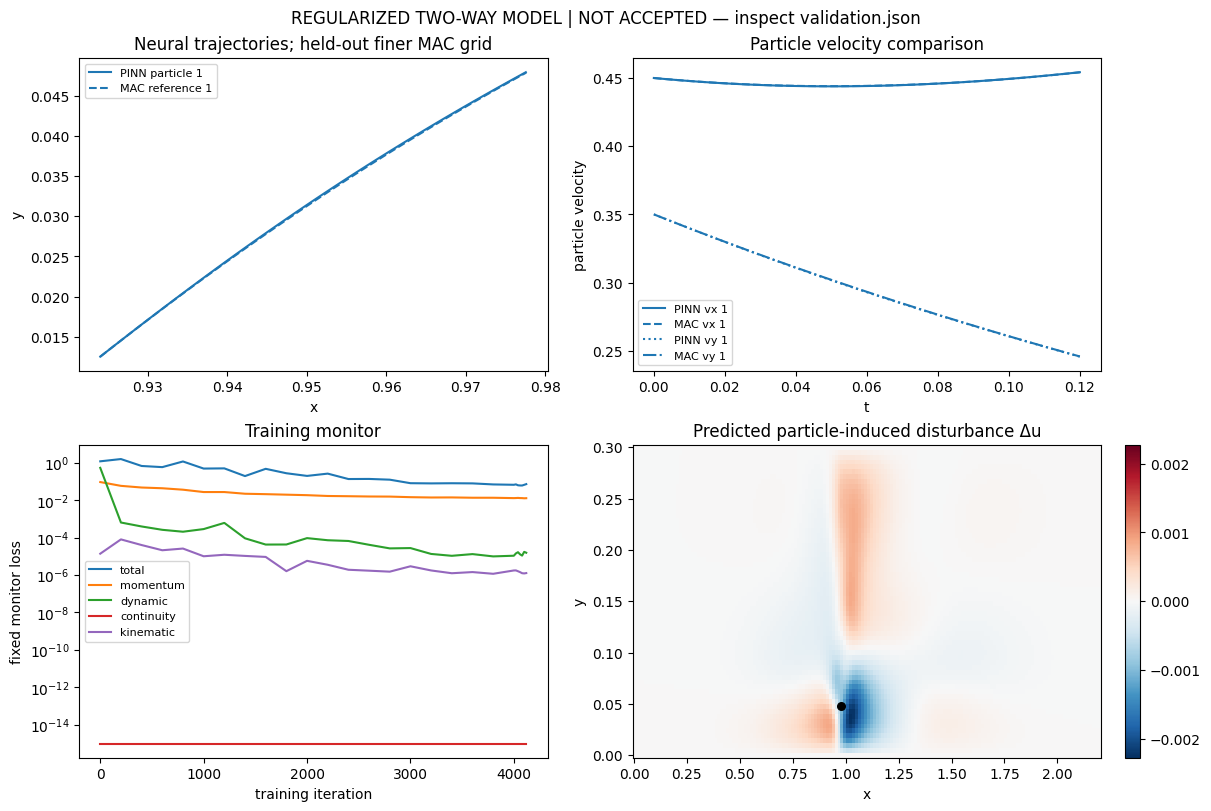

{
  "position_max_abs": 0.0001208534379814,
  "velocity_max_abs": 0.0003010518094213457,
  "streamwise_velocity_relative_l2": 0.00010268827112289084,
  "transverse_velocity_rms_abs": 6.084083995711728e-05,
  "disturbance_u_rms_abs": 7.499354251655668e-05,
  "disturbance_u_relative_l2": 0.30437413634995025,
  "pressure_perturbation_rms_abs": 0.001249682653451832,
  "pressure_perturbation_relative_l2": 0.2521367222460306,
  "disturbance_vector_relative_l2": 0.28322515455862324,
  "numerical_fluid_data_in_training": true,
  "particle_inside_domain": true,
  "min_sampled_pair_distance": null,
  "independent_residuals": {
    "total": 0.01998423682847118,
    "momentum": 0.013973986352229162,
    "continuity": 1.570536971493394e-34,
    "kinematic": 9.443312124118835e-07,
    "dynamic": 1.4870783472088965e-05,
    "outlet": 1.6070398197932287e-10,
    "domain": 0.0,
    "pressure_poisson": 0.019953121161683372
  },
  "reference_max_divergence": 3.713522545023551e-13,
  "reference_dt": 3.278

/kaggle/working/two_way_point_pinn_1793551007180694732/two_way_replay.html

/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


FINAL STATUS: NOT ACCEPTED


In [9]:
if RUN_REFERENCE:
    VALIDATION=run_validation(model,history,RUN,kernel_scan=KERNEL_WIDTH_SCAN)
else:
    VALIDATION={'passed':False,'reason':'Independent reference comparison skipped.'}
    write_json(RUN/'validation.json',VALIDATION)
print('FINAL STATUS:', 'ACCEPTED FOR THIS SCENARIO' if VALIDATION['passed'] else 'NOT ACCEPTED')


## ۸. آزمون پارامترهای دیده‌نشده، اختیاری
فقط پس از آموزش `parametric=True` اجرا کنید. هزینهٔ حل‌های مرجع برای هر نمونه اضافه می‌شود. این آزمون جدا از پذیرش سناریوی پیش‌فرض است.

In [10]:
def held_out_parameter_sweep(model,count=3):
    if not model.cfg.parametric:raise ValueError('Train a parametric model first.')
    rng=np.random.default_rng(model.cfg.seed+1981)
    cases=sample_controls(model.cfg,count+1,rng)[1:]
    rows=[]
    original=model.cfg
    try:
        for index,c in enumerate(cases):
            model.cfg=replace(original,scenario=tuple(c))
            directory=RUN/f'held_out_{index+1}';directory.mkdir()
            report=run_validation(model,history,directory,kernel_scan=False)
            rows.append(dict(case=index+1,controls=c.tolist(),passed=report['passed'],
                             position_error=report['position_max_abs']))
    finally:model.cfg=original
    write_json(RUN/'held_out_parameter_sweep.json',rows)
    return rows

# HELD_OUT_RESULTS=held_out_parameter_sweep(model,3)


## ۹. دریافت فایل‌ها و منابع روش
بسته شامل بهترین وزن، تنظیمات، گزارش آموزش، نتایج آزمون‌ها، حل‌های مرجع، نمودار و نمایشگر آفلاین است. حالت پیش‌فرض یک حل مشخص با horizon کوتاه است؛ بهینه‌سازی شکل‌های قبلی را تا اعتبارسنجی حالت چندذره‌ای به آن وصل نکنید.

اصل عملگرهای خواندن/پخش الحاقی و اهمیت تشخیص سرعت مختل‌شده از بدون‌اغتشاش را می‌توان در منابع زیر پیگیری کرد. مدل اصطکاکیِ این نوت‌بوک عین روش no-slip مقالهٔ اول یا تصحیح سرعتِ مقالهٔ دوم نیست:

- [Balboa Usabiaga et al., Inertial Coupling Method](https://arxiv.org/abs/1212.6427) — اصول عملگرهای الحاقی و مدل blob.
- [Pakseresht & Apte, disturbance-corrected point-particle method](https://arxiv.org/abs/2012.01605) — مسئلهٔ سرعت بدون اغتشاش در بستارهای ذرهٔ نقطه‌ای.
- [Ye et al., partitioned state-exchange Bi-PINNs](https://doi.org/10.1063/5.0347142) — نمونهٔ پژوهشی حل عصبی کوپل دوطرفه.


In [11]:
summary={'model':'finite-width Gaussian filtered-drag two-way PINN',
 'fluid_network_physical_inputs':3+3*cfg.n,'particle_network_inputs':1+3*cfg.n,
 'particle_equations':'learned by neural residuals, not replaced by reference ODE',
 'all_release_times':0,'coarse_fluid_data_requested':USE_COARSE_FLUID_DATA,'direct_particle_contact':False,
 'validation_passed':bool(VALIDATION['passed']),
 'scope':'configured scenario; finite-width model, not resolved sphere dynamics'}
write_json(RUN/'run_summary.json',summary)
archive=shutil.make_archive(str(RUN),'zip',root_dir=RUN)
display(FileLink(archive))


/kaggle/working/two_way_point_pinn_1793551007180694732.zip

## گزارش اجرای نمونهٔ همراه

## اعداد اجرای نمونه، ۱ نوامبر ۲۰۲۶

- بیشینهٔ خطای موقعیت ذره: 2.51676e-05 بی‌بعد
- بیشینهٔ خطای سرعت ذره: 0.000129509
- خطای نسبی L2 سرعت کل سیال در زمان پایانی: 0.00823%
- خطای نسبی بردار اغتشاش: 23.68%
- خطای نسبی مؤلفهٔ طولی اغتشاش: 24.39%
- خطای نسبی اغتشاش فشار: 14.20%
- عدم توازن عددی تبادل داخلی مومنتوم: 2.95e-17
- اختلاف مسیر مرجع با نصف‌شدن گام زمانی: 1.51e-10
- تغییر نسبی اغتشاش مرجع با ریزشدن شبکه: 0.97%

تمام معیارهای تعریف‌شدهٔ مرحلهٔ اول پاس شده‌اند. این عبارت به دقت مدلِ هموارشده در همین سناریو مربوط است، نه اثبات فیزیک کامل کرهٔ واقعی، دقت مقاله‌ای یا تعمیم به شرایط ندیده. به‌خصوص حدود 24% خطای اغتشاش ضعیف هنوز برای گزارش علمی دقیق نیاز به بهبود دارد. خطای کوچک سرعت کل را جای خطای اثر ذره نگذارید.

وزن نمونه حاصل چند مرحلهٔ پیش‌آموزش و اصلاح است. training_history.json فقط آخرین اصلاح مشترک را ثبت می‌کند؛ step آن طول کل آموزش نیست. coarse_initialization_history.json به مرحلهٔ کمکیِ پیش از آخرین اصلاح مربوط است. checkpoint نمونه تضمین نمی‌کند یک اجرای تصادفیِ تازه در همان تعداد گام همگرا شود.

## دامنهٔ مدل

ذرات نقطه‌مانند، با حالت مکان/سرعت و پخش گاوسی نیرو مدل می‌شوند. همان کرنل برای خواندن سرعت و پخش نیروی عکس‌العمل استفاده می‌شود؛ این مدلِ اصطکاکیِ سرعت فیلترشده است و به‌عنوان تصحیح سرعت بدون اغتشاش یا حل سطح کره معرفی نمی‌شود. گرانش، شناوری، لیفت، تاریخچه، جرم افزوده، دوران و تماس مستقیم حذف شده‌اند. عمق خارج صفحه در تبدیل جرم و نیروی سه‌بعدی به سیال دوبعدی صریح است.

همهٔ رهاسازی‌ها در این مرحله t=0 هستند. بهینه‌سازی شکل و برنامهٔ رهاسازیِ نسخهٔ یک‌طرفه به این فایل وصل نشده‌اند. برای دو ذره sides=(0,1) و آموزش تازه بگذارید؛ یک میدان مشترک و جمع منابع نیرو حل می‌شود. برهم‌کنش از طریق سیال وجود دارد، اما جمعِ جواب‌های مستقل و نیروی تماس مستقیم استفاده نمی‌شوند.

